In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import PolynomialFeatures

house_df = pd.read_csv('kc_house_data.csv')

## Exercise 1
a) Create and train simple regression model of sqft_living to price.  
b) Evaluate and visualise created model.  
c) Create and plot higher order polynomial regression models.

Model is trained on 1000 records. model.fit(X, y) finds the intercept and the minimalising line.

In [87]:
#a)

X = house_df.sqft_living.values.reshape(-1,1)[:1000]
y = house_df.price.values.reshape(-1)[:1000]

model = LinearRegression()

#Your code:

model.fit(X, y)

#Hint: .fit()

LinearRegression()

Linear regression: y = b + ax where: b = model.intercept_ ; a = model.coef_ ; x = sqft_living:

y = -32304.654 + 269.462 * sqft_living

This equation gives the estimated price of a house based on its living area in square feet. One additional square foot increases the price by about 269 dollars.

Score = R^2 = 0.497. I found out that living area explains about half of the variation in prices.

Intercept:  -32304.654721028113
Coefficients:  [269.46205468]
Score (R^2):  0.49670880166311393


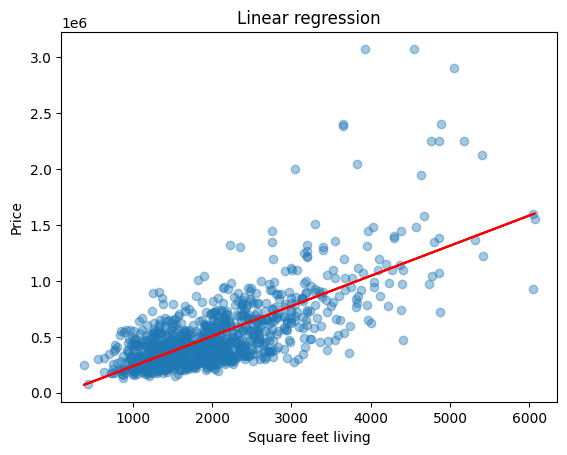

In [88]:
#b)

#Your code:

prediction = model.predict(X)

print("Intercept: ", model.intercept_)
print("Coefficients: ", model.coef_)
print("Score (R^2): ", model.score(X, y))

plt.scatter(X, y, alpha=0.4)
plt.plot(X, prediction, color="red")
plt.xlabel("Square feet living")
plt.ylabel("Price")
plt.title("Linear regression")
plt.show()

#Hint: model.predict(), model.intercept_,  model.coef_, model.score()

(I added list 'error' for collecting Mean Squared Error (MSE) for later analysis)

In below, I checked how MSE changes by used in regression degree of the polynomial. I received the best outcome for the 4' degree. The MSE was 52795774757.6403. The increase in meassured error indicates that calculations propably became numerically unstable.  

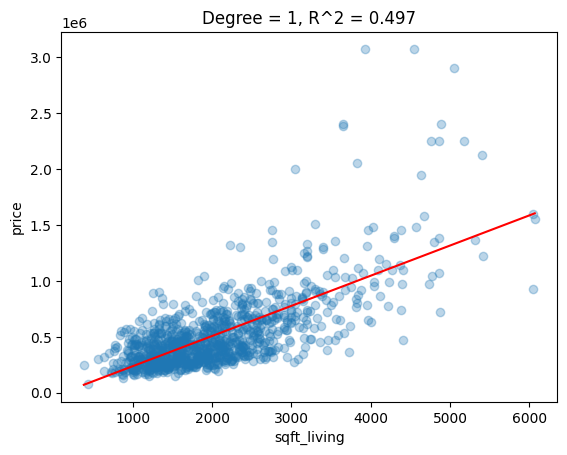

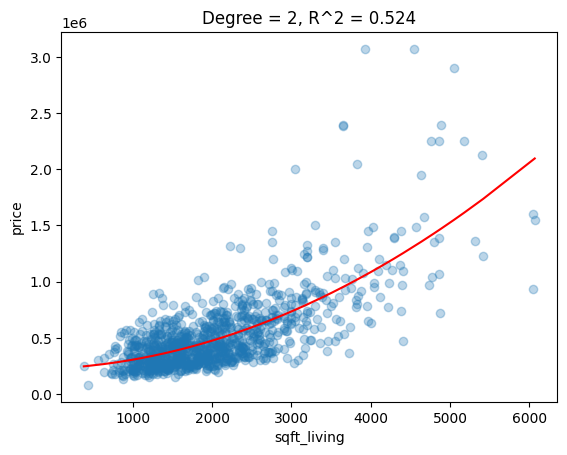

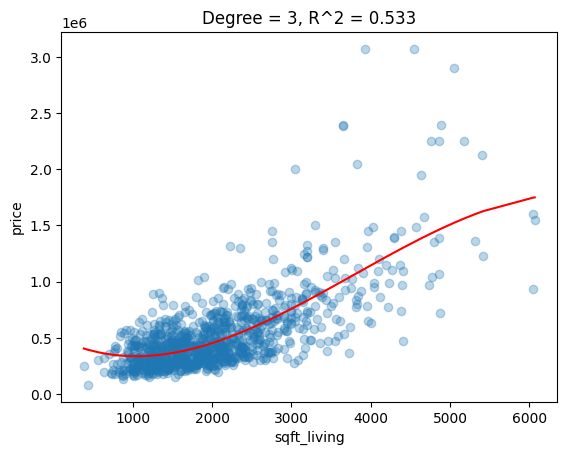

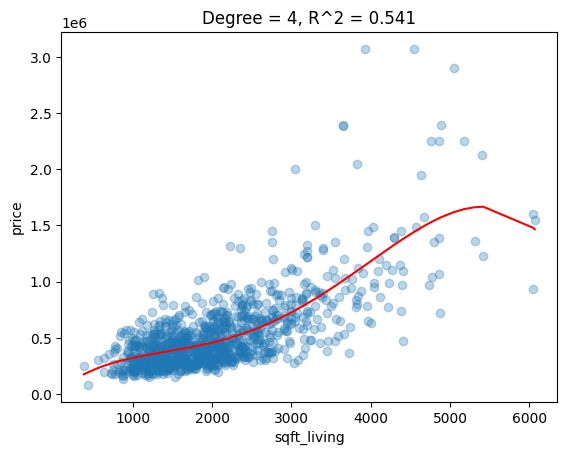

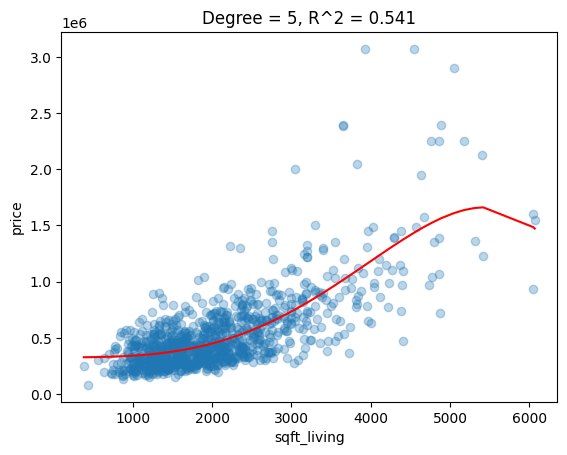

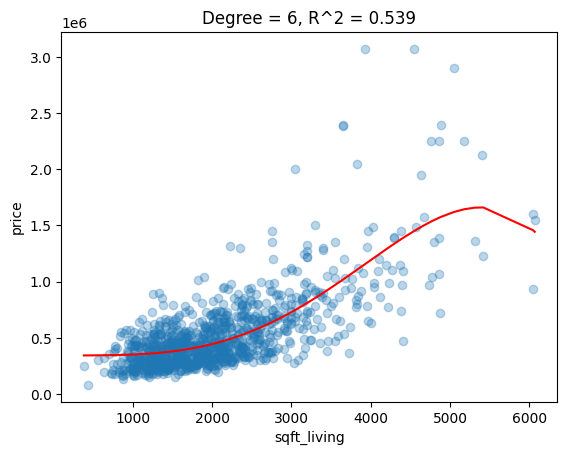

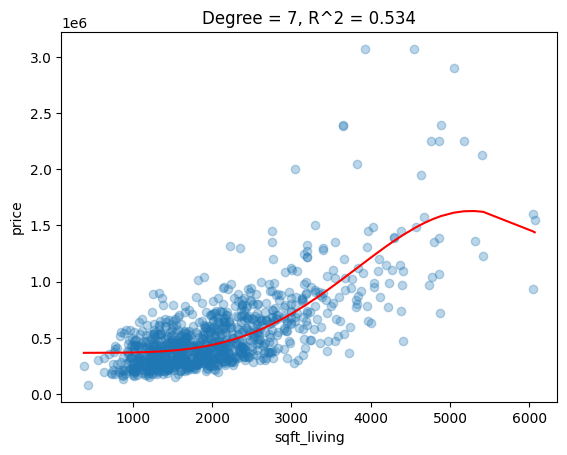

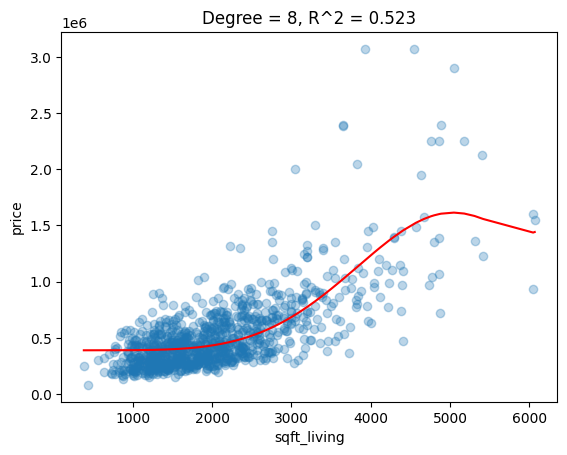

In [89]:
#c)

error = []

for order in range(1,9):

    poly = PolynomialFeatures(order, include_bias = False)
    X_order = poly.fit_transform(X)

    #Your code:

    model = LinearRegression()
    model.fit(X_order, y)
    error.append(mean_squared_error(y, model.predict(X_order)))

    i = np.argsort(X[:,0])
    X_sorted = X[i]
    y_prediction = model.predict(X_order[i])

    plt.figure()
    plt.scatter(X, y, alpha=0.3)
    plt.plot(X_sorted, y_prediction, color="red")
    plt.title(f"Degree = {order}, R^2 = {model.score(X_order, y):.3f}")
    plt.xlabel("sqft_living")
    plt.ylabel("price")
    plt.show()


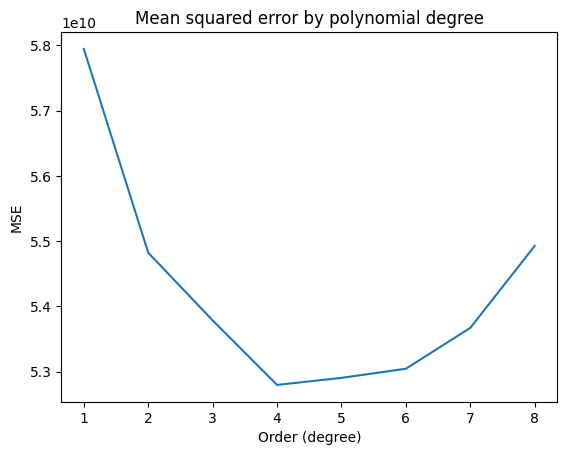

52795774757.6403


In [90]:
#Your code:

plt.figure()
plt.plot(range(1,9), error)
plt.xlabel("Order (degree)")
plt.ylabel("MSE")
plt.title("Mean squared error by polynomial degree")
plt.show()

print(min(error))

## Exercise 2
In reality, we are not given the full dataset, so we need to create models which are able to handle unknown data.  
a) Split your data into training sample and test sample and repeat exercise 1 c). Plot training and test errors for all models.

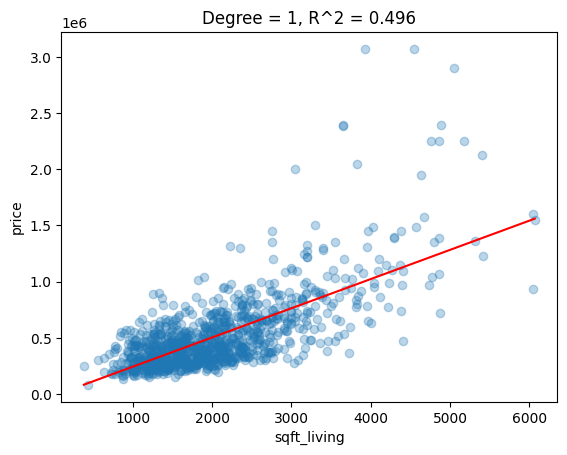

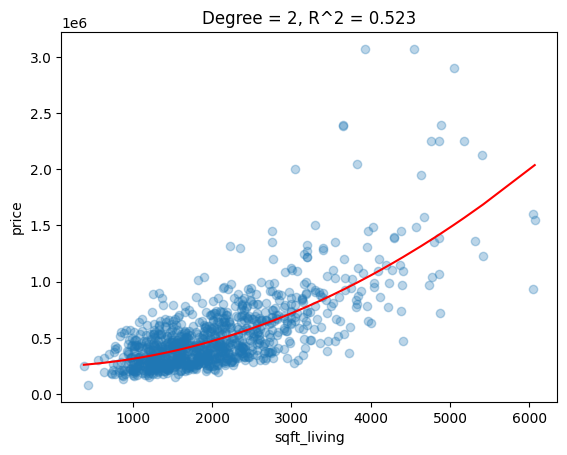

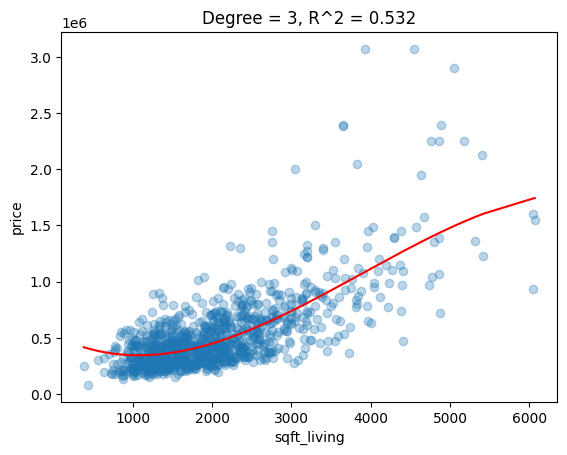

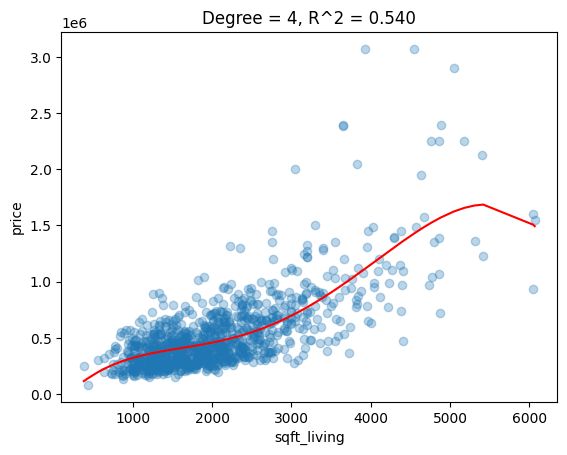

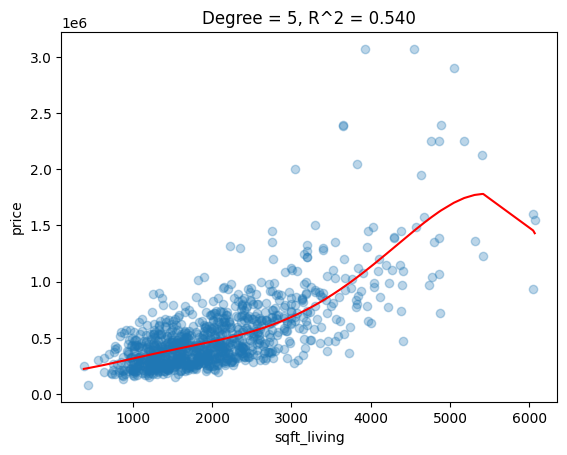

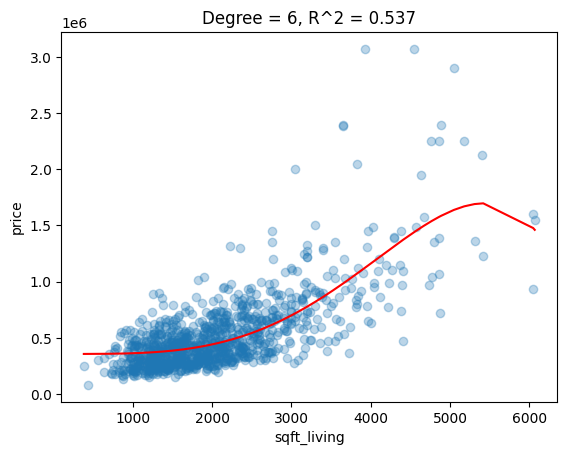

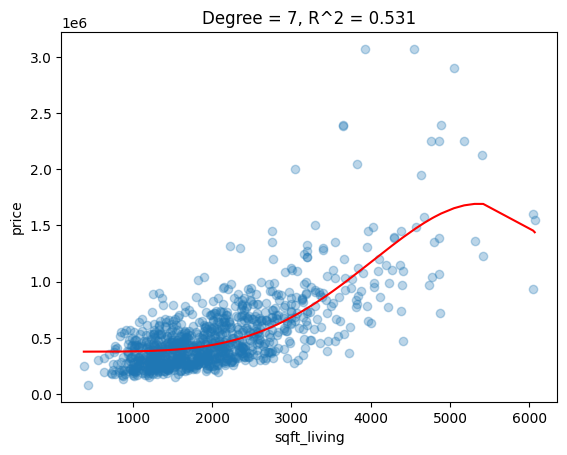

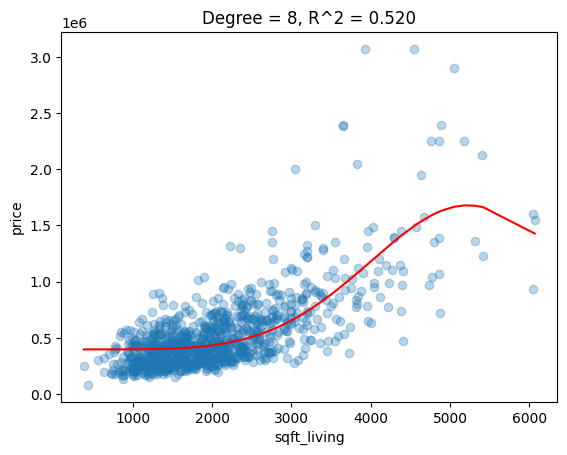

In [91]:
#a)

test_error = []
train_error = []

for order in range(1,9):

    # My code:

    poly = PolynomialFeatures(order, include_bias = False)
    X_order = poly.fit_transform(X)

    X_train, X_test, y_train, y_test = train_test_split(X_order, y, test_size=0.3, random_state=44)

    model = LinearRegression()
    model.fit(X_train, y_train)
    train_error.append(mean_squared_error(y_train, model.predict(X_train)))
    test_error.append(mean_squared_error(y_test, model.predict(X_test)))

    i = np.argsort(X[:,0])
    X_sorted = X[i]
    y_prediction = model.predict(X_order[i])

    plt.figure()
    plt.scatter(X, y, alpha=0.3)
    plt.plot(X_sorted, y_prediction, color="red")
    plt.title(f"Degree = {order}, R^2 = {model.score(X_order, y):.3f}")
    plt.xlabel("sqft_living")
    plt.ylabel("price")
    plt.show()


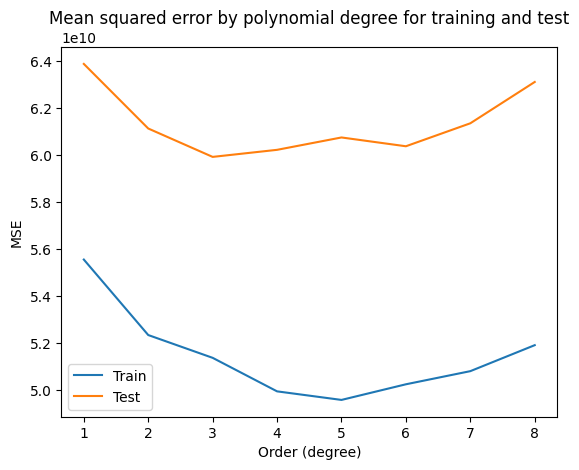

In [92]:

plt.figure()
plt.plot(range(1,9), train_error, label="Train")
plt.plot(range(1,9), test_error, label="Test")
plt.xlabel("Order (degree)")
plt.ylabel("MSE")
plt.title("Mean squared error by polynomial degree for training and test")
plt.legend()
plt.show()

In that exercise I collected data about the MSE in the same way as in exercise 1c.

Firstly I splited data to: training set and test set, and then I checked MSE. Measured error was higher for 'Test' dataset then 'Train'. The best outcome for 'Test' was received for degree 3, then it tends to increase what sugest overfitting.

## Exercise 3
a) Train model to predict sqft_living for a given house price. Plot predictions.  
b) Apply more features and propose better model for predicting house prices. Try to beat proposed one.

Intercept:  1091.8971893889102
Coefficients:  [0.00184333]
Score (R^2):  0.49670880166311404


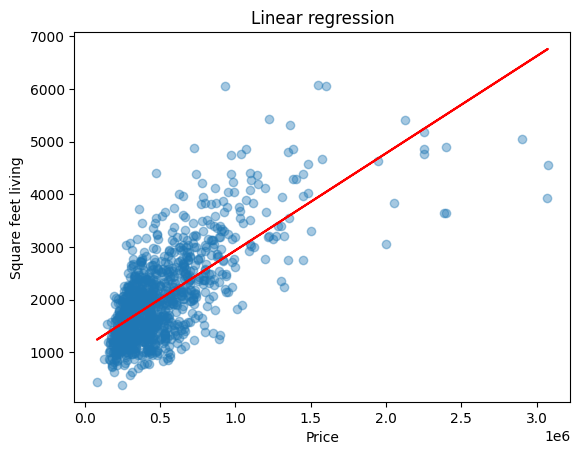

In [93]:
#a)

X = house_df.price.values.reshape(-1,1)[:1000]
y = house_df.sqft_living.values.reshape(-1)[:1000]

#Your code:

model = LinearRegression()
model.fit(X, y)

prediction = model.predict(X)

print("Intercept: ", model.intercept_)
print("Coefficients: ", model.coef_)
print("Score (R^2): ", model.score(X, y))

plt.scatter(X, y, alpha=0.4)
plt.plot(X, prediction, color="red")
plt.ylabel("Square feet living")
plt.xlabel("Price")
plt.title("Linear regression")
plt.show()


I changed the features, now I try to predict the Surface of the house by the Price.

y = 1091.89 + 0.0018 * Price

Score = R^2 = 0.497.

For each 1000$ customer receive about 1,8 square feet of the house.

In [94]:
#b) Let's propose model, which uses living sqft, lot sqft, grade, view and all of their interactions up to third degree

X = house_df[['sqft_living', 'sqft_lot', 'grade', 'view']].values.reshape(-1,4)
y = house_df.price.values.reshape(-1)

poly = PolynomialFeatures(3, include_bias = False)
X = poly.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=43)

model = LinearRegression()
_= model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Mean squared error equals: {0}".format(mean_squared_error(y_pred, y_test)))


Mean squared error equals: 54053591747.298004


In [95]:
# Your model:

X = house_df[['sqft_living', 'sqft_lot', 'grade', 'view', 'bathrooms', 'yr_built', 'lat']].values.reshape(-1,7)
y = house_df.price.values.reshape(-1)

poly = PolynomialFeatures(2, include_bias = False)
X = poly.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=43)

model = LinearRegression()
_= model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Mean squared error equals: {0}".format(mean_squared_error(y_pred, y_test)))

Mean squared error equals: 36526218887.51395


For the proposed model of the data ( house_df[['sqft_living', 'sqft_lot', 'grade', 'view']] ) I received high MSE: 54053591747.298

To lower it, I added more features like ( house_df[['sqft_living', 'sqft_lot', 'grade', 'view', 'bathrooms', 'yr_built', 'lat'] ):

'bathrooms' - number of bathrooms in the house

'yr_built' - year of construction

'lat' - latitude (location)

I also changed the degree to 2 which kept the calculations more stable.

The outcome I received was satisfying. MSE lowered to 36526218887.513 (about 32%). The reason is the fact that price of the house strongly depends on many aspects, overall grade and surface is not enough. Adding features such as year of construction and location to receive more precise predictions.